In [24]:
import sys
sys.path.append("..")
from src.io_utils import load_data
df = load_data("../data/health_study_dataset.csv")

**1. Scatterplotet (spridningsdiagram) hjälper oss att undersöka:**
- Verkar blodtrycket öka med åldern?
- Finns det något samband?
- Hur mycket varierar blodtrycket mellan personer i samma ålder?
- Finns det några avvikande värden?
- OBS: scatterplotet räknar inte ut någon modell. Det visar bara våra observationer.

**2. Linjär regression – beräkna ett samband**
- Nu har vi lagt till en röd linje i diagrammet. Det är en regressionslinje som representerar den linje som bäst sammanfattar det linjära sambandet mellan ålder och blodtryck enligt minsta kvadratmetoden.
- Med den kan vi exempelvis uppskatta: vilket systoliskt blodtryck modellen förväntar sig vid en viss ålder.
- Vår linjära regression kan uppskatta blodtrycket även vid åldrar där vi saknar observationer, eftersom modellen utgår från den övergripande trenden i hela datasetet

**3. Men var kommer signifikans in?**
Här är en viktig skillnad:
- Linjär regression: Vi undersöker och modellerar sambandet mellan två variabler.
- Signifikansanalys: Vi kan undersöka om det finns statistiskt stöd för att sambandet skiljer sig från noll i populationen.
- Vi vill undersöka om lutningen i regressionslinjen är tillräckligt tydlig för att det ska vara osannolikt att den uppstått enbart på grund av slumpmässig variation




#### - Nollhypotes (H₀): Det finns inget linjärt samband mellan ålder och blodtryck (lutningen är 0)
#### - Alternativ hypotes (H₁): Det finns ett linjärt samband (lutningen skiljer sig från 0)

In [25]:
# Beräkna korrelation med Numpy

# KÄLLA: Korrelationsanalys: https://realpython.com/numpy-scipy-pandas-correlation-python/#example-numpy-correlation-calculation

import numpy as np

X = df["age"].values # hämtar värdena från "age" och omvandlar dem till en np-array
Y = df["systolic_bp"].values  # hämtar värdena från "systolic_bp" och omvandlar dem till en np-array
r = np.corrcoef(X, Y) # beräknas korrelationsmatris
print(f"r = {r[0, 1]}") # Hämtar korrelationen mellan X och Y

# Detta gav: r = 0.60757847098565

# TOLKNING: Korrelationen mellan ålder och systoliskt blodtryck är 0,607
# vilket indikerar ett positivt samband som kan bedömas som måttligt till starkt,
# beroende på vilket forskningsområde och vilka tumregler som används

r = 0.60757847098565


### Utökad analys och visualisering
- Lägg till minst en ny analys eller graf som ger en djupare förståelse (t.ex. relationen mellan blodtryck och ålder, eller sjukdomsförekomst per kön).

In [26]:
%pip install skicit-learn

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement skicit-learn (from versions: none)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for skicit-learn


[0.40914325 0.26044863 0.16043484 0.10823539 0.06173789]
                     age    height    weight  systolic_bp  cholesterol
Huvudkomponent                                                        
PC1             0.573224  0.098300  0.247196     0.568990     0.526209
PC2            -0.279984  0.693791  0.657227    -0.059119    -0.069424
PC3             0.277281  0.556410 -0.495263     0.317787    -0.516961
PC4            -0.142505 -0.432574  0.387781     0.570396    -0.562891
PC5             0.704153 -0.110805  0.333596    -0.496402    -0.366319


(800, 3)

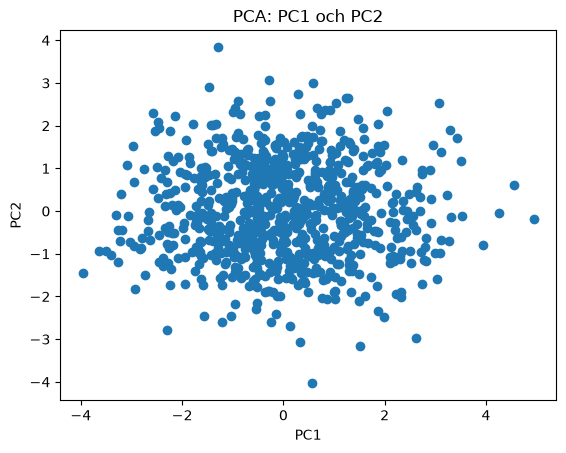

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns

# KÄLLA: PCA-analys: Ryan # Matt Data Science, PCA Analysis in Python Explained (Scikit - Learn) https://www.youtube.com/watch?v=6uwa9EkUqpg

# 1: VÄLJ VARIABLER
# Vi använder fem numeriska variabler i vår första PCA
X = df[["age", "height", "weight", "systolic_bp", "cholesterol"]]

# Vi lämnar sex, smoker och disease utanför själva PCA-beräkningen
# eftersom vi i första steget vill undersöka hur de fem numeriska variablerna samvarierar

# Vi sparar disease för att senare kunna undersöka om personer med olika PC-värden
# också skiljer sig åt när det gäller sjukdomsförekomst


# 2: STANDARDISERA VARIABLERNA
scaler = StandardScaler()  # Skapar ett objekt av klassen StandardScaler som utför standardiseringen
X_scaled = scaler.fit_transform(X)  # Beräknar medelvärde och standardavvikelse och standardiserar variablerna i X
X_scaled.mean(axis=0)  # Kontrollerar medelvärdet för varje standardiserad variabel
X_scaled.std(axis=0)   # Kontrollerar standardavvikelsen för varje standardiserad variabel
# axis=0 innebär att beräkningen görs nedåt längs raderna, alltså kolumn för kolumn
# axis=1 innebär att beräkningen görs vågrätt längs kolumnerna, alltså rad för rad


# 3: BERÄKNA HUVUDKOMPONENTERNA MED PCA
pca = PCA()  # Skapar ett objekt av klassen PCA som utför huvudkomponentanalysen
# PCA analyserar hur de fem variablerna varierar tillsammans
# Beräkningen bygger på variablernas samvariationsstruktur
# Datorn hittar nya riktningar som fångar så mycket variation i datan som möjligt
# Dessa riktningar blir våra nya variabler, huvudkomponenterna (PC1, PC2 osv)

X_pca = pca.fit_transform(X_scaled)  # Anpassar PCA-modellen och omvandlar datan till huvudkomponenter
# fit_transform() anpassar modellen till datan och omvandlar den i ett steg

# 4: UNDERSÖK RESULTATET
X_pca.shape  # Kontrollerar dimensionerna på resultatet från PCA
print(pca.explained_variance_ratio_) # visar hur stor andel av variationerna varje huvudkomponent (PC) fångar
pca.explained_variance_ratio_.cumsum() # visar ackumulerade (sammanlagda) förklarade variationen.
# PCA1: 0.40914325, PCA1-2: 0.66959189, PCA1-3: 0.83002672, PCA1-4: 0.93826211, PCA1-5: 1
pca.components_ # Visar hur de ursprungliga variablerna bidrar till varje huvudkomponent

# 5. TA FRAM DIAGRAM
# Visualierar personerna i datan utifrån deras två första huvudkomponenter
plt.scatter(X_pca[:, 0], X_pca[:, 1])
# X_pca[:, 0] hämtar PC1-värdena för samtliga 800 personer
# X_pca[:, 1] hämtar PC2-värdena för samtliga 800 personer
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: PC1 och PC2")
# plt.show()

# KOMMENTAR
# vad positionerna betyder:

# Långt åt höger (högt PC1): Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# Långt upp (högt PC2): Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt.

pca_components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2", "PC3", "PC4", "PC5"]
).rename_axis("Huvudkomponent")

pc3_components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2", "PC3", "PC4", "PC5"]
).loc["PC3"]

print(pca_components)

X_pca_reduce = X_pca[:, :3] # hämtar PC1-PC3 för samtliga personer
X_pca_reduce.shape

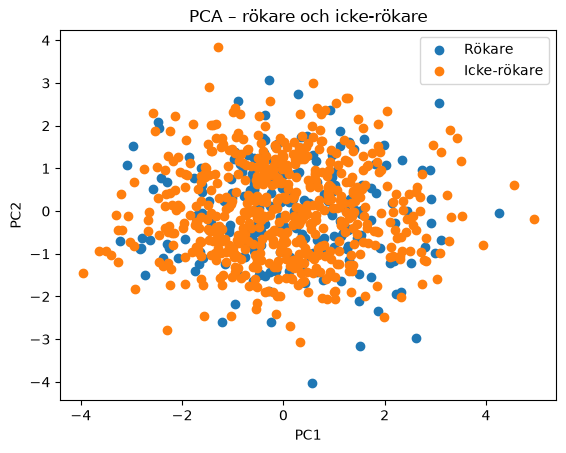

In [28]:
# 6: JÄMFÖR RÖKARE OCH ICKE-RÖKARE I PCA-DIAGRAMMET
plt.scatter(X_pca[df["smoker"] == "Yes", 0],
            X_pca[df["smoker"] == "Yes", 1],
            label="Rökare")

plt.scatter(X_pca[df["smoker"] == "No", 0],
            X_pca[df["smoker"] == "No", 1],
            label="Icke-rökare")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA – rökare och icke-rökare")
plt.legend()
plt.show()

# TOLKNING
# Långt åt höger (högt PC1): Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# Långt upp (högt PC2): Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt.

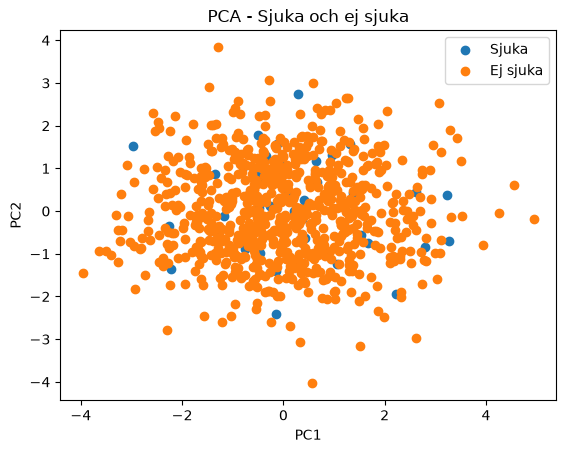

In [ ]:
# 7: JÄMFÖR SJUKA OCH EJ SJUKA I PCA-DIAGRAMMET
plt.scatter(X_pca[df["disease"] == 1, 0],
            X_pca[df["disease"] == 1, 1],
            label="Sjuka")

plt.scatter(X_pca[df["disease"] == 0, 0],
            X_pca[df["disease"] == 0, 1],
            label="Ej sjuka")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Sjuka och ej sjuka")
plt.legend()
plt.show()

# TOLKNING
# Långt åt höger (högt PC1): Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# Långt upp (högt PC2): Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt.




In [ ]:
# 8: 3D-DIAGRAM FÖR PC1-PC3 + RÖKARE OCH ICKE RÖKARE
# KÄLLA: https://python-graph-gallery.com/372-3d-pca-result/

sns.set_style("white") # Anger diagrammets bakgrundsstil till vit, utan rutnät
my_dpi=96              # Anger upplösningen till 96 pixlar per tum
plt.figure(figsize=(480/my_dpi, 480/my_dpi), dpi=my_dpi) # skapa figuren



In [ ]:
# Source - https://stackoverflow.com/a/65242129
# Posted by sai
# Retrieved 2026-11-19, License - CC BY-SA 4.0

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
# %matplotlib notebook

data = load_breast_cancer()
X = data.data
y = data.target
sc = StandardScaler()

scaler = StandardScaler()
scaler.fit(X) 
X_scaled = scaler.transform(X)

pca = PCA(n_components=3)
pca.fit(X_scaled) 
X_pca = pca.transform(X_scaled) 

ex_variance=np.var(X_pca,axis=0)
ex_variance_ratio = ex_variance/np.sum(ex_variance)
ex_variance_ratio

Xax = X_pca[:,0]
Yax = X_pca[:,1]
Zax = X_pca[:,2]

cdict = {0:'red',1:'green'}
labl = {0:'Malignant',1:'Benign'}
marker = {0:'*',1:'o'}
alpha = {0:.3, 1:.5}

fig = plt.figure(figsize=(7,5))
ax = fig.add_subplot(111, projection='3d')

fig.patch.set_facecolor('white')
for l in np.unique(y):
 ix=np.where(y==l)
 ax.scatter(Xax[ix], Yax[ix], Zax[ix], c=cdict[l], s=40,
           label=labl[l], marker=marker[l], alpha=alpha[l])
# for loop ends
ax.set_xlabel("First Principal Component", fontsize=14)
ax.set_ylabel("Second Principal Component", fontsize=14)
ax.set_zlabel("Third Principal Component", fontsize=14)

ax.legend()
plt.show()


In [ ]:

fig = plt.figure(figsize=(7,5))
ax = fig.add_subplot(111, projection='3d')


# 7: JÄMFÖR SJUKA OCH EJ SJUKA I PCA-DIAGRAMMET
plt.scatter(X_pca[df["disease"] == 1, 0],
            X_pca[df["disease"] == 1, 1],
            label="Sjuka")

plt.scatter(X_pca[df["disease"] == 0, 0],
            X_pca[df["disease"] == 0, 1],
            label="Ej sjuka")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Sjuka och ej sjuka")
plt.legend()
plt.show()

# TOLKNING
# Långt åt höger (högt PC1): Personen har ett högt värde på en kombination 
# som framför allt väger in ålder, blodtryck och kolesterol.

# Långt upp (högt PC2): Personen har ett högt värde på en kombination som 
# framför allt väger in längd och vikt.
